In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from network_SIR import load_socio, run_campaign

G = load_socio()
beta = 0.04
gamma = 0.1
n_tests = 10

In [9]:
n_runs = 200
vacc_budgets = [1, 3, 5, 10]
accuracies = [0.5, 0.75, 1.0]

rows = []
for r in range(n_runs):
    out = run_campaign(G, beta, gamma, "none", 0, 0, 1.0, seed=r)
    rows.append({"strategy": "none", "V": 0, "accuracy": np.nan, "run": r, **out})

    for V in vacc_budgets:
        for strategy in ["random", "degree"]:
            out = run_campaign(G, beta, gamma, strategy, V, 0, 1.0, seed=r)
            rows.append({"strategy": strategy, "V": V, "accuracy": np.nan, "run": r, **out})

        for acc in accuracies:
            for strategy in ["combined", "adaptive"]:
                out = run_campaign(G, beta, gamma, strategy, V, n_tests, acc, seed=r)
                rows.append({"strategy": strategy, "V": V, "accuracy": acc, "run": r, **out})

results = pd.DataFrame(rows)
print(len(results), "simulations")

6600 simulations


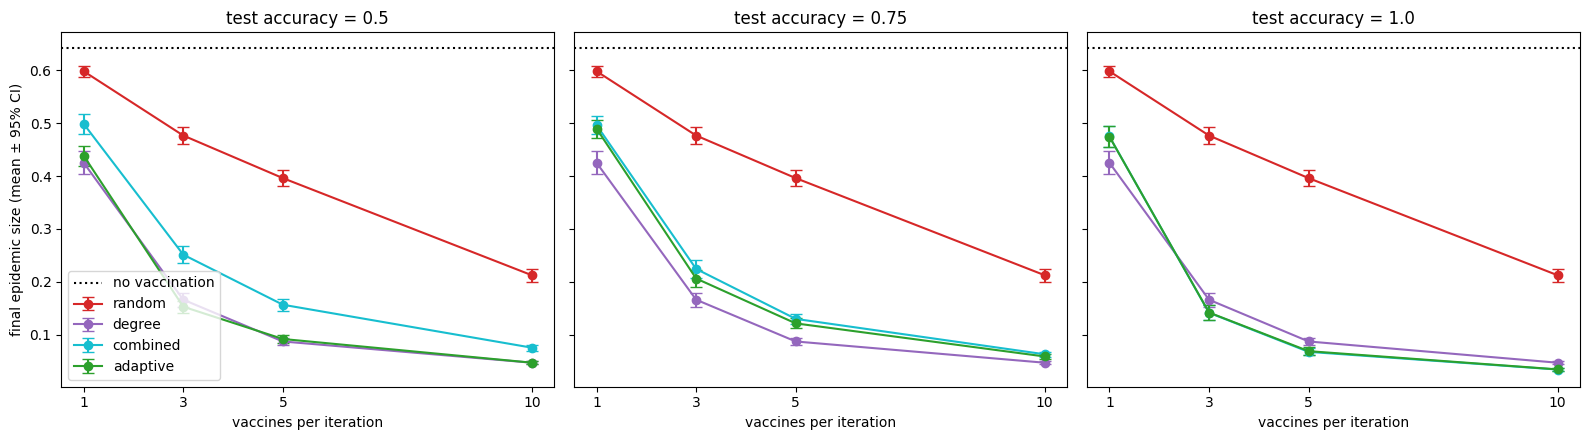

In [10]:
STRAT_COLORS = {"random": "tab:red", "degree": "tab:purple", "combined": "tab:cyan", "adaptive": "tab:green"}

def mean_ci(x):
    return np.mean(x), 1.96 * np.std(x) / np.sqrt(len(x))

none_mean = results[results["strategy"] == "none"]["final_size"].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, acc in zip(axes, accuracies):
    ax.axhline(none_mean, color="black", linestyle=":", label="no vaccination")

    for strategy in ["random", "degree", "combined", "adaptive"]:
        if strategy in ["combined", "adaptive"]:
            sub = results[(results["strategy"] == strategy) & (results["accuracy"] == acc)]
        else:
            sub = results[results["strategy"] == strategy]

        means = []
        cis = []
        for V in vacc_budgets:
            m, ci = mean_ci(sub[sub["V"] == V]["final_size"])
            means.append(m)
            cis.append(ci)

        ax.errorbar(vacc_budgets, means, yerr=cis, marker="o", capsize=4,
                    color=STRAT_COLORS[strategy], label=strategy)

    ax.set_title(f"test accuracy = {acc}")
    ax.set_xlabel("vaccines per iteration")
    ax.set_xticks(vacc_budgets)

axes[0].set_ylabel("final epidemic size (mean ± 95% CI)")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.savefig("figures/vaccination_final_size.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
from scipy.stats import wilcoxon

def get_runs(strategy, V, acc=None):
    sub = results[(results["strategy"] == strategy) & (results["V"] == V)]
    if acc is not None:
        sub = sub[sub["accuracy"] == acc]
    return sub.sort_values("run")["final_size"].values

def paired_test(x, y):
    if np.all(x == y):
        return 1.0
    return wilcoxon(x, y).pvalue

rows = []
for V in vacc_budgets:
    rand = get_runs("random", V)
    deg = get_runs("degree", V)

    cases = [("degree", None)]
    for acc in accuracies:
        cases += [("combined", acc), ("adaptive", acc)]

    for strategy, acc in cases:
        x = get_runs(strategy, V, acc)
        rows.append({
            "V": V,
            "strategy": strategy,
            "accuracy": acc if acc is not None else "-",
            "final size": np.mean(x),
            "reduction vs random": 1 - np.mean(x) / np.mean(rand),
            "p vs random": paired_test(x, rand),
            "difference vs degree": np.mean(x) - np.mean(deg),
            "p vs degree": paired_test(x, deg) if strategy != "degree" else np.nan,
        })

stats_table = pd.DataFrame(rows)

n_comparisons = stats_table["p vs random"].notna().sum() + stats_table["p vs degree"].notna().sum()
alpha = 0.05 / n_comparisons
print("number of tests:", n_comparisons, "| Bonferroni threshold:", round(alpha, 5))

stats_table["significant vs degree"] = stats_table["p vs degree"].map(
    lambda p: "-" if pd.isna(p) else ("yes" if p < alpha else "no"))

display_table = stats_table.copy()
display_table["p vs random"] = display_table["p vs random"].map(lambda p: f"{p:.1e}")
display_table["p vs degree"] = display_table["p vs degree"].map(lambda p: "-" if pd.isna(p) else f"{p:.1e}")
display_table.round(4)

number of tests: 52 | Bonferroni threshold: 0.00096


,V,strategy,accuracy,final size,reduction vs random,p vs random,difference vs degree,p vs degree,significant vs degree
0,1,degree,-,0.4251,0.2893,4.1e-30,0.0000,-,-
1,1,combined,0.5,0.4986,0.1664,5.8e-23,0.0735,4.0e-09,yes
2,1,adaptive,0.5,0.4383,0.2672,7.9e-31,0.0133,7.8e-01,no
3,1,combined,0.75,0.4962,0.1704,1.1e-23,0.0711,9.0e-08,yes
4,1,adaptive,0.75,0.4896,0.1815,3.0e-25,0.0645,6.4e-06,yes
5,1,combined,1.0,0.4748,0.2062,2.0e-27,0.0497,1.0e-04,yes
6,1,adaptive,1.0,0.4745,0.2067,1.8e-27,0.0494,1.1e-04,yes
7,3,degree,-,0.1659,0.6518,6.4e-34,0.0000,-,-
8,3,combined,0.5,0.2512,0.4729,1.0e-29,0.0852,1.3e-14,yes
9,3,adaptive,0.5,0.1527,0.6796,4.6e-34,-0.0132,8.4e-02,no


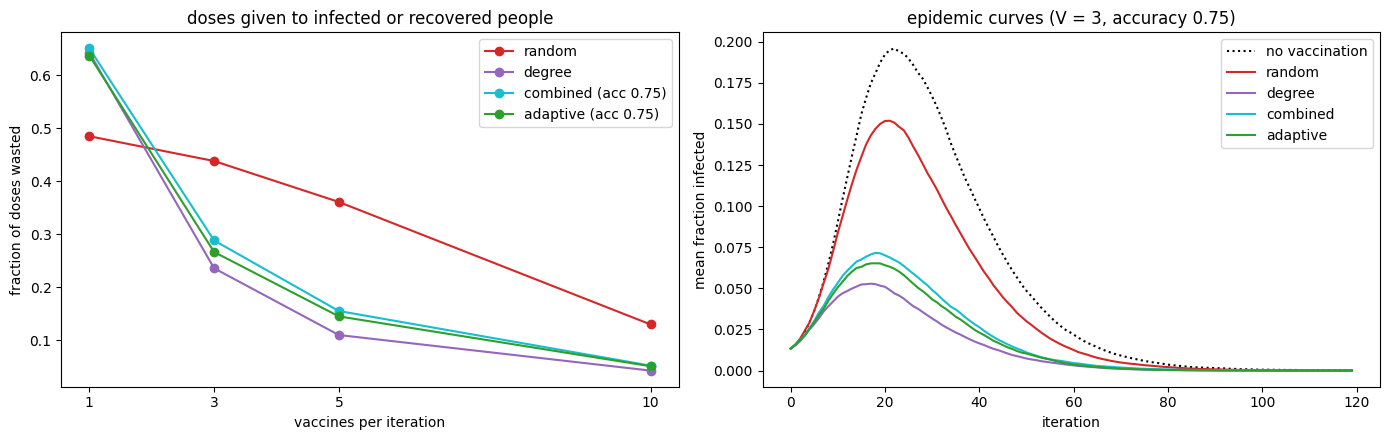

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for strategy in ["random", "degree", "combined", "adaptive"]:
    if strategy in ["combined", "adaptive"]:
        sub = results[(results["strategy"] == strategy) & (results["accuracy"] == 0.75)]
        label = strategy + " (acc 0.75)"
    else:
        sub = results[results["strategy"] == strategy]
        label = strategy
    wasted_frac = []
    for V in vacc_budgets:
        s = sub[sub["V"] == V]
        doses = s["wasted"].sum()
        total = 0
        for _, row in s.iterrows():
            total += V * (len(row["I"]))
        wasted_frac.append(doses / total)
    axes[0].plot(vacc_budgets, wasted_frac, marker="o", color=STRAT_COLORS[strategy], label=label)

axes[0].set_xlabel("vaccines per iteration")
axes[0].set_ylabel("fraction of doses wasted")
axes[0].set_title("doses given to infected or recovered people")
axes[0].set_xticks(vacc_budgets)
axes[0].legend()

V_show = 3
T = 120
none_curves = [np.pad(I, (0, max(0, T - len(I))), mode="edge")[:T]
               for I in results[results["strategy"] == "none"]["I"]]
axes[1].plot(np.mean(none_curves, axis=0), color="black", linestyle=":", label="no vaccination")

for strategy in ["random", "degree", "combined", "adaptive"]:
    if strategy in ["combined", "adaptive"]:
        sub = results[(results["strategy"] == strategy) & (results["accuracy"] == 0.75) & (results["V"] == V_show)]
    else:
        sub = results[(results["strategy"] == strategy) & (results["V"] == V_show)]
    curves = [np.pad(I, (0, max(0, T - len(I))), mode="edge")[:T] for I in sub["I"]]
    axes[1].plot(np.mean(curves, axis=0), color=STRAT_COLORS[strategy], label=strategy)

axes[1].set_xlabel("iteration")
axes[1].set_ylabel("mean fraction infected")
axes[1].set_title(f"epidemic curves (V = {V_show}, accuracy 0.75)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/vaccination_wasted_and_curves.png", dpi=200, bbox_inches="tight")
plt.show()

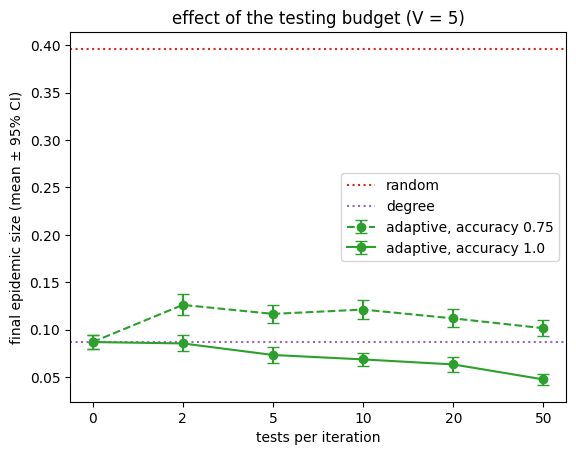

In [14]:
test_budgets = [0, 2, 5, 10, 20, 50]
V_test = 5
n_runs_tests = 200

rows = []
for r in range(n_runs_tests):
    for acc in [0.75, 1.0]:
        for nt in test_budgets:
            out = run_campaign(G, beta, gamma, "adaptive", V_test, nt, acc, seed=r)
            rows.append({"accuracy": acc, "n_tests": nt, "run": r, "final_size": out["final_size"]})

test_results = pd.DataFrame(rows)

for acc, style in [(0.75, "--"), (1.0, "-")]:
    means = []
    cis = []
    for nt in test_budgets:
        m, ci = mean_ci(test_results[(test_results["accuracy"] == acc) & (test_results["n_tests"] == nt)]["final_size"])
        means.append(m)
        cis.append(ci)
    plt.errorbar(range(len(test_budgets)), means, yerr=cis, marker="o", capsize=4, linestyle=style,
                 color=STRAT_COLORS["adaptive"], label=f"adaptive, accuracy {acc}")

for strategy in ["random", "degree"]:
    m = results[(results["strategy"] == strategy) & (results["V"] == V_test)]["final_size"].mean()
    plt.axhline(m, color=STRAT_COLORS[strategy], linestyle=":", label=strategy)

plt.xticks(range(len(test_budgets)), test_budgets)
plt.xlabel("tests per iteration")
plt.ylabel("final epidemic size (mean ± 95% CI)")
plt.title(f"effect of the testing budget (V = {V_test})")
plt.legend()
plt.savefig("figures/vaccination_test_budget.png", dpi=200, bbox_inches="tight")
plt.show()